# Demand Forecasting & Inventory Planning

## Business Problem

Retail businesses need to anticipate future demand to make better operational
decisions. Poor demand forecasting can contribute to stockouts, excess
inventory, inefficient staffing, and missed sales opportunities.

This project analyzes historical retail sales data and develops a forecasting
model to estimate future demand. The forecasts will then be translated into a
simple inventory-planning framework to demonstrate how predictive analytics
can support business decision-making.

## Project Objectives

- Analyze historical sales patterns and trends.
- Investigate the effects of promotions, holidays, store characteristics, and
  other factors on sales.
- Identify seasonal and recurring demand patterns.
- Engineer time-series features for forecasting.
- Build and compare baseline and machine-learning forecasting models.
- Evaluate forecasts using appropriate regression metrics.
- Translate demand forecasts into an inventory-planning framework.
- Develop business recommendations from the analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
store = pd.read_csv("../data/store.csv")

C:\Users\DELL\AppData\Local\Temp\ipykernel_28268\801007824.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("../data/train.csv")


In [3]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Store shape:", store.shape)

Train shape: (1017209, 9)
Test shape: (41088, 8)
Store shape: (1115, 10)


In [4]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [5]:
test.head()

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [6]:
test.head()

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 69.8+ MB


In [8]:
store.info()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 87.2 KB


In [9]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             41088 non-null  int64  
 1   Store          41088 non-null  int64  
 2   DayOfWeek      41088 non-null  int64  
 3   Date           41088 non-null  str    
 4   Open           41077 non-null  float64
 5   Promo          41088 non-null  int64  
 6   StateHoliday   41088 non-null  str    
 7   SchoolHoliday  41088 non-null  int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 2.5 MB


In [10]:
print("Earliest date:", train["Date"].min())
print("Latest date:", train["Date"].max())

Earliest date: 2013-01-01
Latest date: 2015-07-31


In [12]:
print("Number of stores:", train["Store"].nunique())
print("Number of training records:", len(train))

Number of stores: 1115
Number of training records: 1017209


In [13]:
train.isnull().sum().sort_values(ascending=False)

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [14]:
store.isnull().sum().sort_values(ascending=False)

PromoInterval                544
Promo2SinceYear              544
Promo2SinceWeek              544
CompetitionOpenSinceYear     354
CompetitionOpenSinceMonth    354
CompetitionDistance            3
StoreType                      0
Store                          0
Assortment                     0
Promo2                         0
dtype: int64

In [15]:
train["Date"].dtype

<StringDtype(storage='python', na_value=nan)>

In [16]:
train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])

In [17]:
print(train["Date"].dtype)
print(train["Date"].min())
print(train["Date"].max())

datetime64[us]
2013-01-01 00:00:00
2015-07-31 00:00:00


## Data Preparation

The `Date` column was converted to datetime format to support chronological
analysis, time-based feature engineering, and forecasting.

In [19]:
print("Duplicate training rows:", train.duplicated().sum())
print("Duplicate store rows:", store.duplicated().sum())

Duplicate training rows: 0
Duplicate store rows: 0


In [20]:
train.duplicated(subset=["Store", "Date"]).sum()

np.int64(0)

In [21]:
missing_store = pd.DataFrame({
    "Missing_Count": store.isnull().sum(),
    "Missing_Percentage": store.isnull().mean() * 100
})

missing_store = missing_store[
    missing_store["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

missing_store

,Missing_Count,Missing_Percentage
Promo2SinceYear,544,48.789238
Promo2SinceWeek,544,48.789238
PromoInterval,544,48.789238
CompetitionOpenSinceMonth,354,31.748879
CompetitionOpenSinceYear,354,31.748879
CompetitionDistance,3,0.269058


In [22]:
train[["Sales", "Customers"]].describe()

,Sales,Customers
count,1.017209e+06,1.017209e+06
mean,5.773819e+03,6.331459e+02
std,3.849926e+03,4.644117e+02
min,0.000000e+00,0.000000e+00
25%,3.727000e+03,4.050000e+02
50%,5.744000e+03,6.090000e+02
75%,7.856000e+03,8.370000e+02
max,4.155100e+04,7.388000e+03


In [23]:
train["Open"].value_counts(dropna=False)

Open
1    844392
0    172817
Name: count, dtype: int64

In [24]:
(train["Sales"] == 0).value_counts()

Sales
False    844338
True     172871
Name: count, dtype: int64

In [25]:
train.loc[
    train["Sales"] == 0,
    ["Store", "Date", "Open", "Sales", "Customers", "Promo"]
].head(20)

,Store,Date,Open,Sales,Customers,Promo
291,292,2015-07-31,0,0,0,1
875,876,2015-07-31,0,0,0,1
1406,292,2015-07-30,0,0,0,1
1990,876,2015-07-30,0,0,0,1
2521,292,2015-07-29,0,0,0,1
3105,876,2015-07-29,0,0,0,1
3636,292,2015-07-28,0,0,0,1
4220,876,2015-07-28,0,0,0,1
4751,292,2015-07-27,0,0,0,1
5335,876,2015-07-27,0,0,0,1


In [26]:
pd.crosstab(
    train["Open"],
    train["Sales"] == 0,
    margins=True
)

Sales,False,True,All
Open,,,
0,0,172817,172817
1,844338,54,844392
All,844338,172871,1017209


In [27]:
open_zero_sales = train[
    (train["Open"] == 1) &
    (train["Sales"] == 0)
]

print("Open stores with zero sales:", len(open_zero_sales))

open_zero_sales.head(20)

Open stores with zero sales: 54


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
86825,971,5,2015-05-15,0,0,1,0,0,1
142278,674,4,2015-03-26,0,0,1,0,0,0
196938,699,4,2015-02-05,0,0,1,1,0,0
322053,708,3,2014-10-01,0,0,1,1,0,0
330176,357,1,2014-09-22,0,0,1,0,0,0
340348,227,4,2014-09-11,0,0,1,0,0,0
340860,835,4,2014-09-11,0,0,1,0,0,0
341795,835,3,2014-09-10,0,0,1,0,0,0
346232,548,5,2014-09-05,0,0,1,1,0,1
346734,28,4,2014-09-04,0,0,1,1,0,0


In [28]:
categorical_cols = [
    "DayOfWeek",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday"
]

for col in categorical_cols:
    print(f"\n{col}")
    print(train[col].value_counts(dropna=False))


DayOfWeek
DayOfWeek
5    145845
4    145845
3    145665
2    145664
1    144730
7    144730
6    144730
Name: count, dtype: int64

Open
Open
1    844392
0    172817
Name: count, dtype: int64

Promo
Promo
0    629129
1    388080
Name: count, dtype: int64

StateHoliday
StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64

SchoolHoliday
SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64


In [29]:
store_categorical_cols = [
    "StoreType",
    "Assortment",
    "Promo2",
    "PromoInterval"
]

for col in store_categorical_cols:
    print(f"\n{col}")
    print(store[col].value_counts(dropna=False))


StoreType
StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

Assortment
Assortment
a    593
c    513
b      9
Name: count, dtype: int64

Promo2
Promo2
1    571
0    544
Name: count, dtype: int64

PromoInterval
PromoInterval
NaN                 544
Jan,Apr,Jul,Oct     335
Feb,May,Aug,Nov     130
Mar,Jun,Sept,Dec    106
Name: count, dtype: int64


In [30]:
df = train.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

In [31]:
print("Train shape:", train.shape)
print("Merged shape:", df.shape)

Train shape: (1017209, 9)
Merged shape: (1017209, 18)


In [32]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [33]:
df["StoreType"].isnull().sum()

np.int64(0)

In [34]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)
df["Quarter"] = df["Date"].dt.quarter

In [35]:
df[
    ["Date", "Year", "Month", "Day", "WeekOfYear", "Quarter", "DayOfWeek"]
].head()

,Date,Year,Month,Day,WeekOfYear,Quarter,DayOfWeek
0,2015-07-31,2015,7,31,31,3,5
1,2015-07-31,2015,7,31,31,3,5
2,2015-07-31,2015,7,31,31,3,5
3,2015-07-31,2015,7,31,31,3,5
4,2015-07-31,2015,7,31,31,3,5


In [36]:
df = df.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

In [37]:
df[df["Store"] == 1][
    ["Store", "Date", "Sales"]
].head(10)

,Store,Date,Sales
0,1,2013-01-01,0
1,1,2013-01-02,5530
2,1,2013-01-03,4327
3,1,2013-01-04,4486
4,1,2013-01-05,4997
5,1,2013-01-06,0
6,1,2013-01-07,7176
7,1,2013-01-08,5580
8,1,2013-01-09,5471
9,1,2013-01-10,4892


### Leakage Consideration

The `Customers` variable is useful for exploratory analysis because customer
traffic is strongly related to sales. However, same-day customer counts would
not normally be known when forecasting future sales.

Therefore, `Customers` will be excluded as a direct predictor from the
forecasting models to avoid using information unavailable at prediction time.

In [38]:
df["Sales"].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

In [39]:
print(f"Total Sales: {df['Sales'].sum():,.0f}")
print(f"Average Daily Store Sales: {df['Sales'].mean():,.2f}")
print(f"Median Daily Store Sales: {df['Sales'].median():,.2f}")
print(f"Maximum Daily Store Sales: {df['Sales'].max():,.0f}")

Total Sales: 5,873,180,623
Average Daily Store Sales: 5,773.82
Median Daily Store Sales: 5,744.00
Maximum Daily Store Sales: 41,551


In [40]:
closed = df[df["Open"] == 0]

print("Closed store records:", len(closed))
print("Percentage closed:", round(len(closed) / len(df) * 100, 2), "%")

Closed store records: 172817
Percentage closed: 16.99 %


In [41]:
closed["Sales"].describe()

count    172817.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: Sales, dtype: float64

In [42]:
df_open = df[df["Open"] == 1].copy()

In [43]:
print("All records:", len(df))
print("Open-store records:", len(df_open))

All records: 1017209
Open-store records: 844392


### Open vs. Closed Stores

Closed-store observations contain structural zero sales because the store was
not operating. For analyses focused on customer demand and sales behavior,
open-store observations are analyzed separately to prevent closure days from
artificially lowering sales estimates.

The original observations are retained for later forecasting decisions.

In [44]:
daily_sales = (
    df.groupby("Date", as_index=False)["Sales"]
    .sum()
)

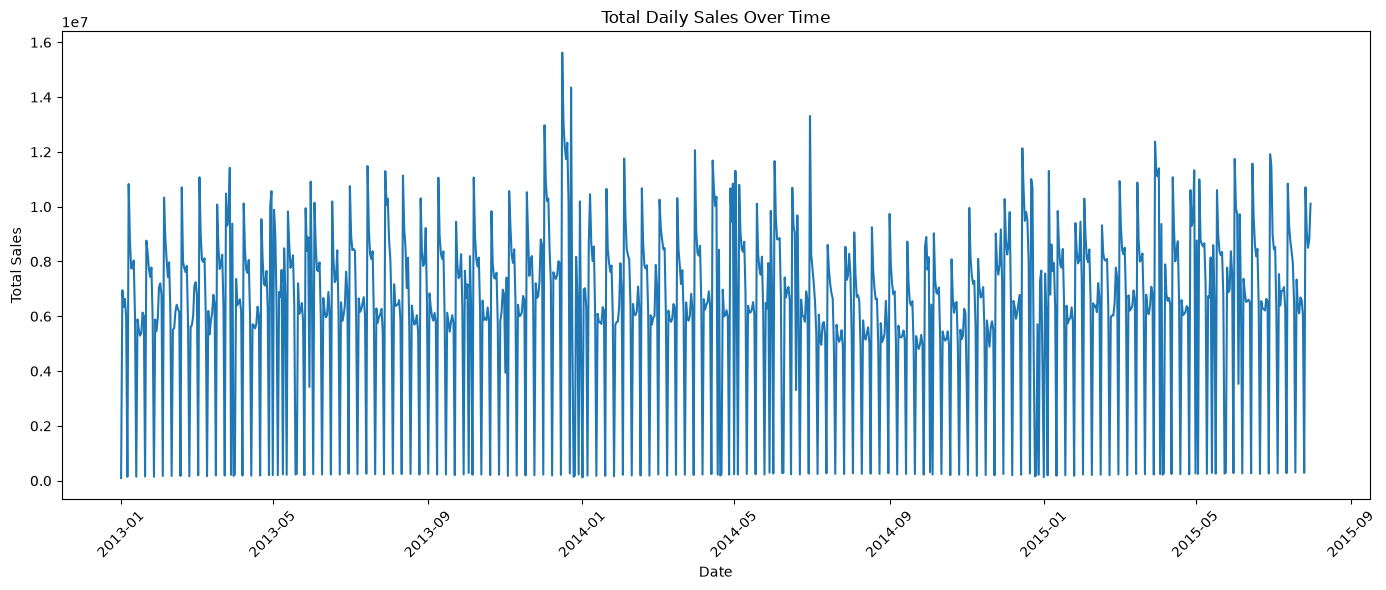

In [45]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Sales"
)

plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
daily_sales["Rolling30"] = (
    daily_sales["Sales"]
    .rolling(window=30)
    .mean()
)

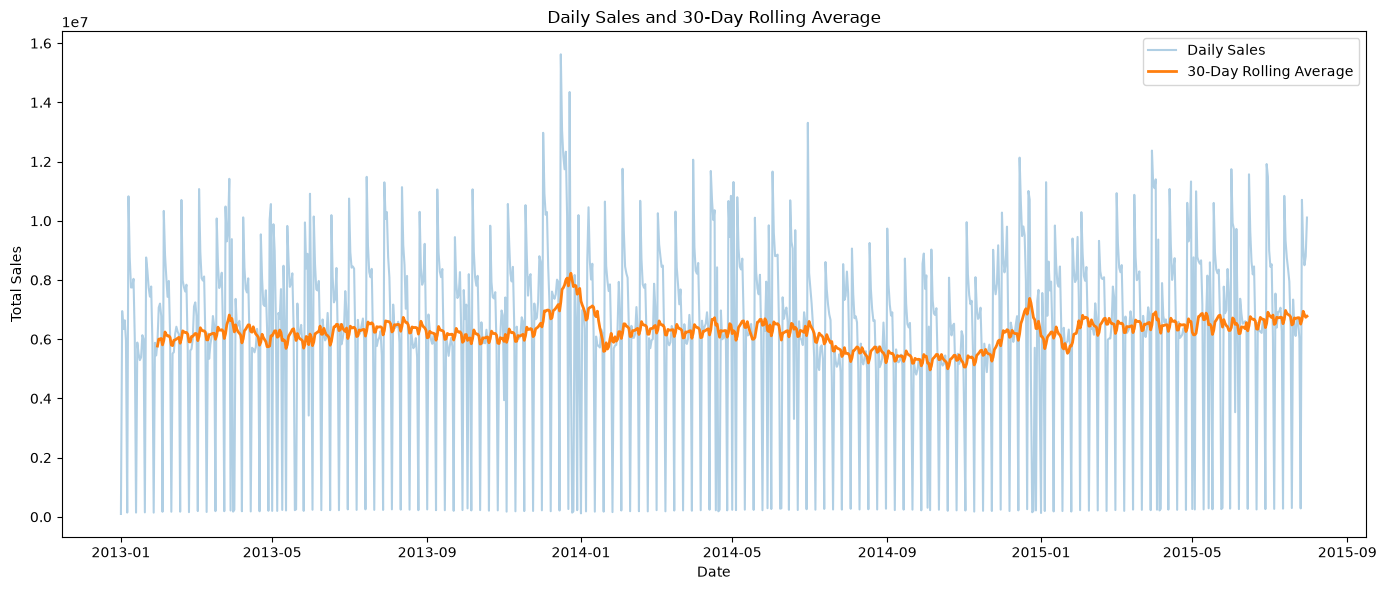

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Sales"],
    alpha=0.35,
    label="Daily Sales"
)

plt.plot(
    daily_sales["Date"],
    daily_sales["Rolling30"],
    linewidth=2,
    label="30-Day Rolling Average"
)

plt.title("Daily Sales and 30-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
weekday_sales = (
    df_open.groupby("DayOfWeek")["Sales"]
           .mean()
           .reset_index()
)

weekday_sales

,DayOfWeek,Sales
0,1,8216.073074
1,2,7088.113656
2,3,6728.122978
3,4,6767.310159
4,5,7072.677012
5,6,5874.840238
6,7,8224.723908


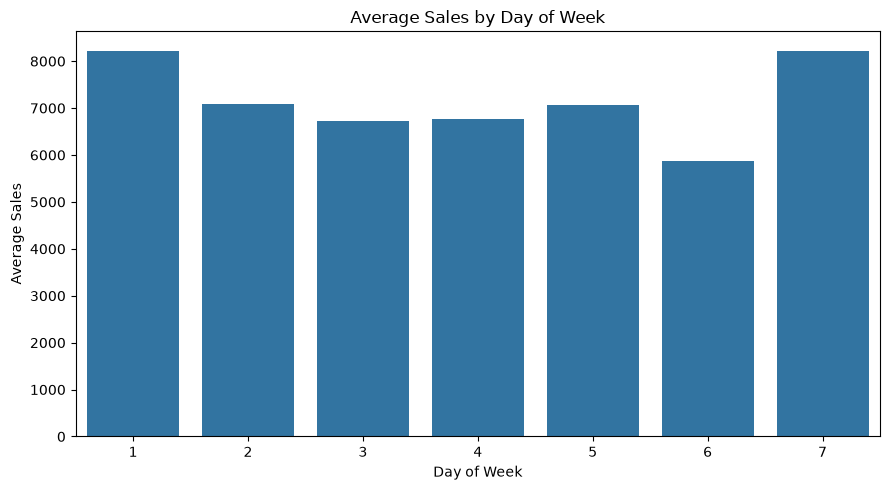

In [49]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=weekday_sales,
    x="DayOfWeek",
    y="Sales"
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

In [50]:
monthly_sales = (
    df_open.groupby("Month")["Sales"]
           .mean()
           .reset_index()
)

monthly_sales

,Month,Sales
0,1,6563.690444
1,2,6589.165535
2,3,6976.412026
3,4,7046.228420
4,5,7106.453154
5,6,7000.978190
6,7,6952.682125
7,8,6648.984654
8,9,6546.343035
9,10,6602.843354


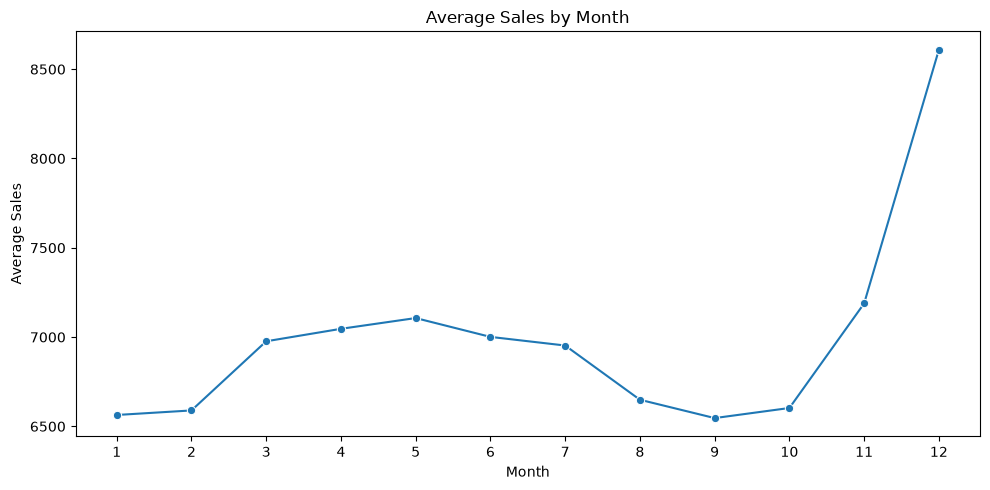

In [51]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    marker="o"
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [52]:
monthly_trend = (
    df.groupby(
        df["Date"].dt.to_period("M")
    )["Sales"]
    .sum()
    .reset_index()
)

monthly_trend["Date"] = monthly_trend["Date"].dt.to_timestamp()

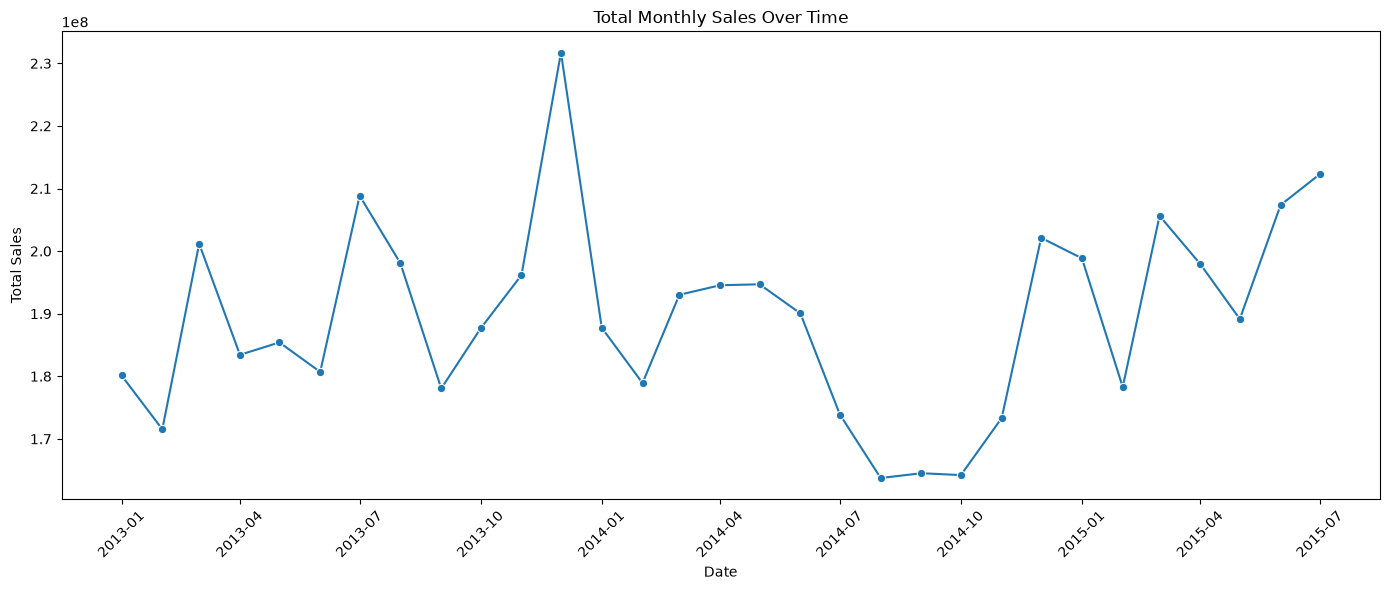

In [53]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_trend,
    x="Date",
    y="Sales",
    marker="o"
)

plt.title("Total Monthly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
promo_sales = (
    df_open.groupby("Promo")["Sales"]
           .agg(["mean", "median", "count"])
)

promo_sales

,mean,median,count
Promo,,,
0,5929.407603,5459.0,467496
1,8228.281239,7649.0,376896


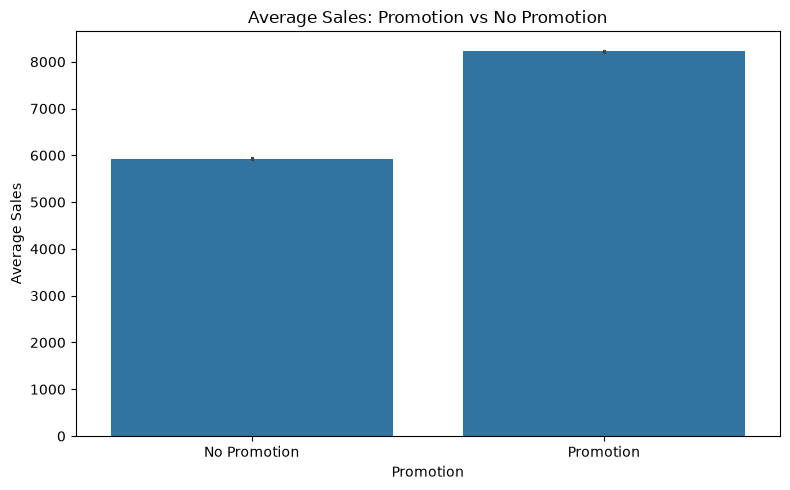

In [55]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_open,
    x="Promo",
    y="Sales"
)

plt.title("Average Sales: Promotion vs No Promotion")
plt.xlabel("Promotion")
plt.ylabel("Average Sales")
plt.xticks([0, 1], ["No Promotion", "Promotion"])
plt.tight_layout()
plt.show()

In [56]:
promo_mean = df_open.groupby("Promo")["Sales"].mean()

promo_difference = (
    (promo_mean[1] - promo_mean[0])
    / promo_mean[0]
) * 100

print(
    f"Average sales were {promo_difference:.2f}% higher "
    "on promotional days."
)

Average sales were 38.77% higher on promotional days.


In [58]:
store_type_sales = (
    df_open.groupby("StoreType")["Sales"]
           .agg(["mean", "median", "count"])
           .sort_values("mean", ascending=False)
)

store_type_sales

,mean,median,count
StoreType,,,
b,10231.407505,9130.0,15563
c,6932.512755,6407.0,112978
a,6925.167661,6285.0,457077
d,6822.141881,6395.0,258774


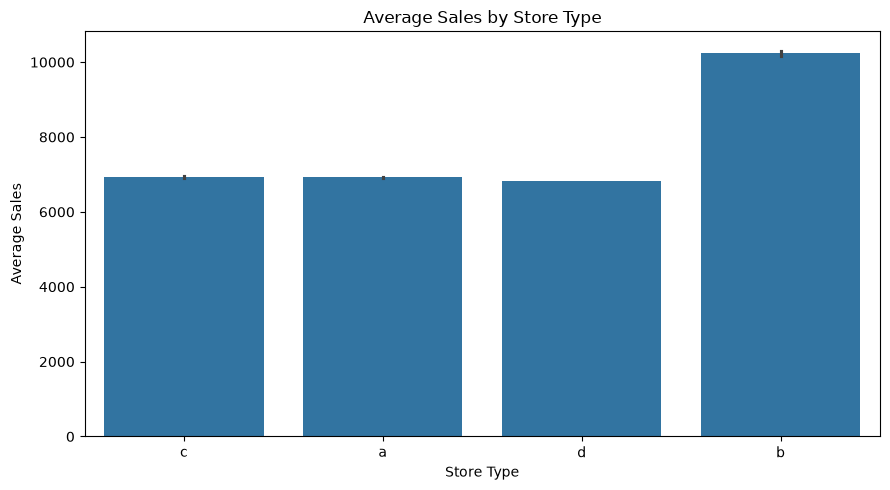

In [59]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_open,
    x="StoreType",
    y="Sales"
)

plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

In [60]:
assortment_sales = (
    df_open.groupby("Assortment")["Sales"]
           .agg(["mean", "median", "count"])
)

assortment_sales

,mean,median,count
Assortment,,,
a,6621.017039,6082.0,444909
b,8639.346322,8081.0,8212
c,7300.526339,6675.0,391271


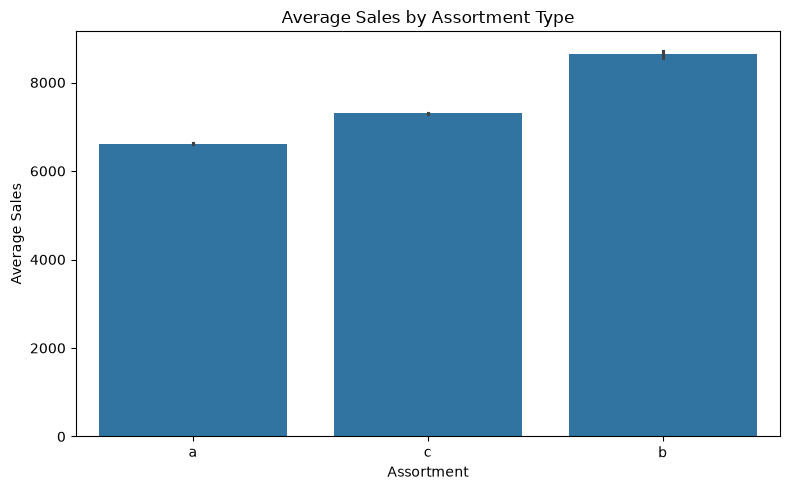

In [61]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_open,
    x="Assortment",
    y="Sales"
)

plt.title("Average Sales by Assortment Type")
plt.xlabel("Assortment")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

In [63]:
store_performance = (
    df_open.groupby("Store")["Sales"]
           .agg(["mean", "std", "min", "max", "count"])
)

store_performance.head()

,mean,std,min,max,count
Store,,,,,
1,4759.096031,1012.106393,2362,9528,781
2,4953.900510,1610.149102,1919,10682,784
3,6942.568678,2193.383804,2936,15689,779
4,9638.401786,1936.031881,5869,17412,784
5,4676.274711,1765.745628,1423,11692,779


In [64]:
store_performance.sort_values(
    "mean",
    ascending=False
).head(10)

,mean,std,min,max,count
Store,,,,,
817,21757.483418,4674.803920,6052,38025,784
262,20718.515924,4668.877584,13210,38722,942
1114,20666.562500,3452.938601,8880,35697,784
251,19123.068036,3547.641612,8373,35350,779
842,18574.795820,3788.985548,7769,35154,622
513,18179.089286,3284.600584,8267,31094,784
562,17969.556263,2931.927599,8498,28680,942
788,17961.914541,3150.647649,10408,32170,784
383,17294.716667,2785.813354,8786,28426,780


In [65]:
store_performance.sort_values(
    "mean"
).head(10)

,mean,std,min,max,count
Store,,,,,
307,2703.736573,1032.828693,811,6951,782
543,2790.380282,1237.698497,506,8754,781
198,2900.604859,1597.761904,530,10676,782
208,2936.290816,716.525610,1546,5864,784
841,2972.608974,1096.262686,958,7020,780
254,3005.983312,832.141965,582,6114,779
794,3083.812821,575.952359,1652,5920,780
219,3133.712452,822.266544,1218,5801,779
210,3193.984596,849.289001,1318,6221,779


In [66]:
store_performance["CV"] = (
    store_performance["std"] /
    store_performance["mean"]
)

In [67]:
store_performance.sort_values(
    "CV",
    ascending=False
).head(10)

,mean,std,min,max,count,CV
Store,,,,,,
198,2900.604859,1597.761904,530,10676,782,0.550837
897,3492.944730,1810.461801,1095,20167,778,0.518320
607,3901.910486,1879.566980,695,10794,782,0.481704
126,6507.753530,3049.536739,1025,33071,779,0.468601
575,5367.566613,2472.728592,1849,17313,623,0.460680
708,4571.989826,2070.314067,0,24975,688,0.452826
589,4672.622193,2113.234629,0,19781,757,0.452259
543,2790.380282,1237.698497,506,8754,781,0.443559
876,9228.909922,4079.722505,1740,27330,766,0.442059


In [68]:
df_open[["Sales", "Customers"]].corr()

,Sales,Customers
Sales,1.000000,0.823597
Customers,0.823597,1.000000


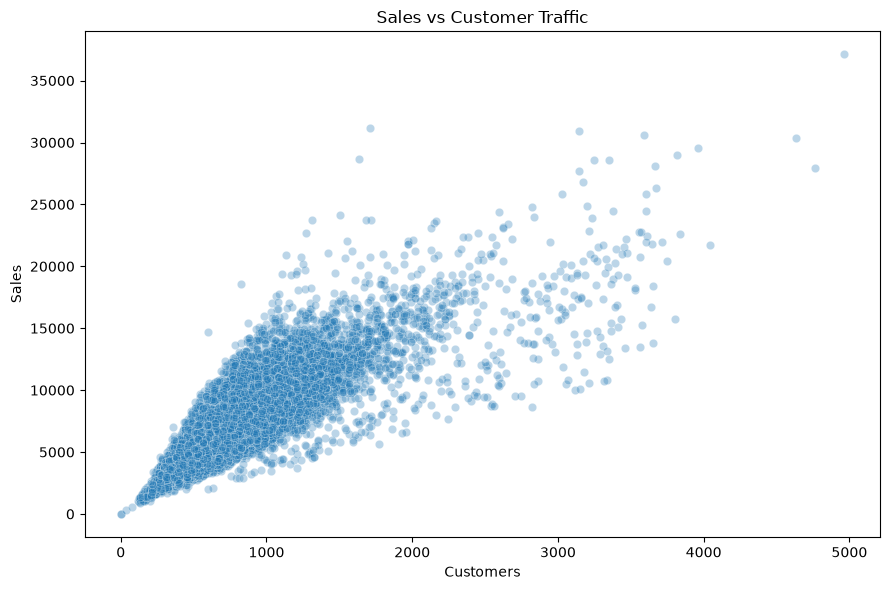

In [69]:
sample_df = df_open.sample(
    n=min(20000, len(df_open)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_df,
    x="Customers",
    y="Sales",
    alpha=0.3
)

plt.title("Sales vs Customer Traffic")
plt.xlabel("Customers")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [70]:
df_open["StateHoliday"].value_counts(dropna=False)

StateHoliday
0    731342
0    112140
a       694
b       145
c        71
Name: count, dtype: int64

In [71]:
holiday_sales = (
    df_open.groupby("StateHoliday")["Sales"]
           .agg(["mean", "median", "count"])
)

holiday_sales

,mean,median,count
StateHoliday,,,
0,6701.492117,6163.0,112140
0,6992.158856,6400.0,731342
a,8487.471182,7556.0,694
b,9887.889655,8423.0,145
c,9743.746479,8397.0,71


In [72]:
school_holiday_sales = (
    df_open.groupby("SchoolHoliday")["Sales"]
           .agg(["mean", "median", "count"])
)

school_holiday_sales

,mean,median,count
SchoolHoliday,,,
0,6896.782411,6326.0,680935
1,7200.181650,6562.0,163457


### Weekly Sales Pattern — Finding

Average sales vary considerably across the week, indicating a clear weekly
demand pattern. Sunday and Monday record the highest average sales among open
stores, at approximately 8,225 and 8,216 respectively, while Saturday records
the lowest average sales at approximately 5,875.

The variation suggests that day of the week contains useful predictive
information and should be incorporated into the demand forecasting model.

### Promotion and Sales — Finding

Promotional periods are associated with substantially higher sales. Open stores
recorded average sales of approximately 8,228 on promotional days compared with
5,929 on non-promotional days, representing an increase of approximately 38.8%.

Median sales show a similar pattern, increasing from 5,459 without promotions
to 7,649 during promotional periods. This suggests that promotion status
contains valuable information for demand forecasting and should be included as
a predictor in the forecasting models.

However, this analysis identifies an association rather than a causal effect;
other factors may also differ between promotional and non-promotional periods.

### Store Type and Sales — Finding

Sales performance varies across store types. Store Type B records the highest
average sales at approximately 10,231, substantially exceeding Store Types A,
C, and D, whose average sales are approximately 6,800–6,900.

Median sales show a similar pattern, with Store Type B recording a median of
9,130 compared with approximately 6,300–6,400 for the other store types.

However, Store Type B has considerably fewer observations than the other
categories, so these differences should be interpreted cautiously. The results
nevertheless suggest that store type contains useful information about demand
and should be retained as a feature in the forecasting model.

### Store-Level Demand Volatility — Finding

Demand stability varies considerably across individual stores. The coefficient
of variation (CV), calculated as the standard deviation of sales divided by
mean sales, was used to compare relative sales volatility across stores.

Store 198 recorded the highest CV at approximately 0.551, followed by Store
897 at 0.518 and Store 607 at 0.482. The results also show that volatility is
not determined solely by average sales volume; both lower-sales and
higher-sales stores appear among the most volatile locations.

This variation suggests that store-specific historical demand patterns are
important for forecasting. From a planning perspective, stores with similar
average demand may require different strategies when one experiences
substantially greater demand variability.

Some open-store observations also contain zero sales, indicating that zero
sales should not automatically be interpreted as a store closure.

### Sales Trend Over Time — Finding

Daily total sales exhibit substantial short-term variation throughout the
historical period. Applying a 30-day rolling average reveals a clearer
underlying demand pattern that is obscured by the volatility of individual
days.

The smoothed series shows periods of both rising and declining demand,
including a pronounced increase around late 2013 and early 2014, weaker
demand during part of the second half of 2014, and a subsequent recovery.

These patterns indicate that demand is not constant over time. Historical
sales behavior, calendar effects, store operating patterns, promotions, and
other business factors may therefore provide useful information for
forecasting future sales.

## Key EDA Findings

The exploratory analysis identified several patterns relevant to demand
forecasting:

1. **Demand changes over time.** Daily sales are highly variable, while the
   30-day rolling average reveals periods of increasing and decreasing
   underlying demand.

2. **A strong weekly pattern exists.** Among open stores, Sunday and Monday
   recorded the highest average sales at approximately 8,225 and 8,216,
   respectively, while Saturday recorded the lowest average sales at
   approximately 5,875.

3. **Promotions are strongly associated with higher sales.** Average sales
   were approximately 8,228 on promotional days compared with 5,929 on
   non-promotional days, representing a difference of approximately 38.8%.

4. **Demand differs across store types.** Store Type B recorded average sales
   of approximately 10,231, considerably higher than Store Types A, C, and D,
   whose averages were approximately 6,800–6,900. Store Type B, however, also
   had substantially fewer observations, so the difference should be
   interpreted cautiously.

5. **Demand volatility varies across stores.** Store 198 had the highest
   coefficient of variation among the examined stores at approximately 0.551,
   demonstrating that stores with different sales volumes can also exhibit
   substantially different levels of demand stability.

6. **Zero sales do not always indicate closure.** Some records for stores
   marked as open contained zero sales, so zero-sales observations should not
   automatically be treated as closed-store records.

Overall, the EDA supports incorporating historical sales, calendar variables,
promotion status, store characteristics, and recent demand behavior into the
forecasting models.

In [75]:
df_model = df.copy()

df_model = df_model.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

print(df_model.shape)

df_model.head()

(1017209, 23)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear,Quarter
0,1,2,2013-01-01,0,0,0,0,a,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,2013,1,1,1,1
1,1,3,2013-01-02,5530,668,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,2013,1,2,1,1
2,1,4,2013-01-03,4327,578,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,2013,1,3,1,1
3,1,5,2013-01-04,4486,619,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,2013,1,4,1,1
4,1,6,2013-01-05,4997,635,1,0,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,2013,1,5,1,1


In [76]:
df_model[
    ["Store", "Date", "Sales"]
].tail(15)

,Store,Date,Sales
1017194,1115,2015-07-17,7874
1017195,1115,2015-07-18,7264
1017196,1115,2015-07-19,0
1017197,1115,2015-07-20,6083
1017198,1115,2015-07-21,5074
1017199,1115,2015-07-22,5342
1017200,1115,2015-07-23,6150
1017201,1115,2015-07-24,5816
1017202,1115,2015-07-25,6897
1017203,1115,2015-07-26,0


In [77]:
print(df_model.shape)
df_model[["Store", "Date", "Sales"]].head(15)

(1017209, 23)


,Store,Date,Sales
0,1,2013-01-01,0
1,1,2013-01-02,5530
2,1,2013-01-03,4327
3,1,2013-01-04,4486
4,1,2013-01-05,4997
5,1,2013-01-06,0
6,1,2013-01-07,7176
7,1,2013-01-08,5580
8,1,2013-01-09,5471
9,1,2013-01-10,4892


In [78]:
df_model.groupby("Store")["Sales"].shift(7)

0             NaN
1             NaN
2             NaN
3             NaN
4             NaN
            ...  
1017204    6083.0
1017205    5074.0
1017206    5342.0
1017207    6150.0
1017208    5816.0
Name: Sales, Length: 1017209, dtype: float64

In [79]:
date_gaps = (
    df_model.groupby("Store")["Date"]
            .diff()
            .dt.days
)

date_gaps.value_counts().sort_index()

Date
1.0      1015914
185.0        180
Name: count, dtype: int64

In [80]:
date_gaps.describe()

count    1.016094e+06
mean     1.032595e+00
std      2.448775e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.850000e+02
Name: Date, dtype: float64

In [81]:
date_gaps.value_counts().sort_index()

Date
1.0      1015914
185.0        180
Name: count, dtype: int64

In [82]:
date_gaps.describe()

count    1.016094e+06
mean     1.032595e+00
std      2.448775e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.850000e+02
Name: Date, dtype: float64

In [83]:
large_gaps = df_model.loc[
    date_gaps > 1,
    ["Store", "Date", "Sales"]
].copy()

large_gaps["GapDays"] = date_gaps[date_gaps > 1]

large_gaps.head(20)

,Store,Date,Sales,GapDays
11850,13,2015-01-01,0,185.0
18260,20,2015-01-01,0,185.0
19960,22,2015-01-01,0,185.0
29196,32,2015-01-01,0,185.0
32780,36,2015-01-01,0,185.0
37306,41,2015-01-01,0,185.0
41832,46,2015-01-01,0,185.0
46358,51,2015-01-01,0,185.0
47116,52,2015-01-01,0,185.0
52584,58,2015-01-01,0,185.0


In [84]:
large_gaps["GapDays"].value_counts()

GapDays
185.0    180
Name: count, dtype: int64

In [85]:
large_gaps["Store"].nunique()

180

In [86]:
sales_lookup = df_model[
    ["Store", "Date", "Sales"]
].copy()

In [87]:
for lag in [1, 7, 14, 28]:
    
    lag_lookup = sales_lookup.copy()
    
    lag_lookup["Date"] = (
        lag_lookup["Date"]
        + pd.Timedelta(days=lag)
    )
    
    lag_lookup = lag_lookup.rename(
        columns={"Sales": f"Sales_Lag_{lag}"}
    )
    
    df_model = df_model.merge(
        lag_lookup,
        on=["Store", "Date"],
        how="left"
    )

In [88]:
df_model[
    [
        "Store",
        "Date",
        "Sales",
        "Sales_Lag_1",
        "Sales_Lag_7",
        "Sales_Lag_14",
        "Sales_Lag_28"
    ]
].head(35)

,Store,Date,Sales,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14,Sales_Lag_28
0,1,2013-01-01,0,NaN,NaN,NaN,NaN
1,1,2013-01-02,5530,0.0,NaN,NaN,NaN
2,1,2013-01-03,4327,5530.0,NaN,NaN,NaN
3,1,2013-01-04,4486,4327.0,NaN,NaN,NaN
4,1,2013-01-05,4997,4486.0,NaN,NaN,NaN
5,1,2013-01-06,0,4997.0,NaN,NaN,NaN
6,1,2013-01-07,7176,0.0,NaN,NaN,NaN
7,1,2013-01-08,5580,7176.0,0.0,NaN,NaN
8,1,2013-01-09,5471,5580.0,5530.0,NaN,NaN
9,1,2013-01-10,4892,5471.0,4327.0,NaN,NaN


In [89]:
df_model.loc[
    (df_model["Store"] == 13) &
    (df_model["Date"].between("2014-12-25", "2015-02-05")),
    [
        "Date",
        "Sales",
        "Sales_Lag_1",
        "Sales_Lag_7",
        "Sales_Lag_14",
        "Sales_Lag_28"
    ]
]

,Date,Sales,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14,Sales_Lag_28
11850,2015-01-01,0,NaN,NaN,NaN,NaN
11851,2015-01-02,4348,0.0,NaN,NaN,NaN
11852,2015-01-03,4066,4348.0,NaN,NaN,NaN
11853,2015-01-04,0,4066.0,NaN,NaN,NaN
11854,2015-01-05,10460,0.0,NaN,NaN,NaN
11855,2015-01-06,0,10460.0,NaN,NaN,NaN
11856,2015-01-07,6988,0.0,NaN,NaN,NaN
11857,2015-01-08,6405,6988.0,0.0,NaN,NaN
11858,2015-01-09,6241,6405.0,4348.0,NaN,NaN
11859,2015-01-10,4315,6241.0,4066.0,NaN,NaN


In [90]:
df_model[
    [
        "Sales_Lag_1",
        "Sales_Lag_7",
        "Sales_Lag_14",
        "Sales_Lag_28"
    ]
].isnull().sum()

Sales_Lag_1      1295
Sales_Lag_7      9065
Sales_Lag_14    18130
Sales_Lag_28    36260
dtype: int64

In [91]:
for lag in range(1, 29):

    col = f"Sales_Lag_{lag}"

    if col in df_model.columns:
        continue

    lag_lookup = sales_lookup.copy()

    lag_lookup["Date"] = (
        lag_lookup["Date"]
        + pd.Timedelta(days=lag)
    )

    lag_lookup = lag_lookup.rename(
        columns={"Sales": col}
    )

    df_model = df_model.merge(
        lag_lookup,
        on=["Store", "Date"],
        how="left"
    )

In [92]:
df_model["RollingMean_7"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 8)]
].mean(axis=1)

df_model["RollingMean_14"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 15)]
].mean(axis=1)

df_model["RollingMean_28"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 29)]
].mean(axis=1)

In [93]:
df_model["RollingMean_7"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 8)]
].mean(axis=1, skipna=False)

df_model["RollingMean_14"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 15)]
].mean(axis=1, skipna=False)

df_model["RollingMean_28"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 29)]
].mean(axis=1, skipna=False)

In [94]:
df_model["RollingStd_7"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 8)]
].std(axis=1, skipna=False)

df_model["RollingStd_28"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 29)]
].std(axis=1, skipna=False)

In [96]:
df_model["RollingMin_7"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 8)]
].min(axis=1, skipna=False)

df_model["RollingMax_7"] = df_model[
    [f"Sales_Lag_{i}" for i in range(1, 8)]
].max(axis=1, skipna=False)

In [97]:
rolling_features = [
    "RollingMean_7",
    "RollingMean_14",
    "RollingMean_28",
    "RollingStd_7",
    "RollingStd_28",
    "RollingMin_7",
    "RollingMax_7"
]

df_model[rolling_features].isnull().sum()

RollingMean_7      9065
RollingMean_14    18130
RollingMean_28    36260
RollingStd_7       9065
RollingStd_28     36260
RollingMin_7       9065
RollingMax_7       9065
dtype: int64

In [98]:
df_model_clean = df_model.dropna(
    subset=["RollingMean_28"]
).copy()

print("Original rows:", len(df_model))
print("Modeling rows:", len(df_model_clean))
print(
    "Rows removed:",
    len(df_model) - len(df_model_clean)
)

Original rows: 1017209
Modeling rows: 980949
Rows removed: 36260


In [99]:
model_history_features = [
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Lag_28",
    "RollingMean_7",
    "RollingMean_14",
    "RollingMean_28",
    "RollingStd_7",
    "RollingStd_28",
    "RollingMin_7",
    "RollingMax_7"
]

df_model_clean[
    model_history_features
].isnull().sum()

Sales_Lag_1       0
Sales_Lag_7       0
Sales_Lag_14      0
Sales_Lag_28      0
RollingMean_7     0
RollingMean_14    0
RollingMean_28    0
RollingStd_7      0
RollingStd_28     0
RollingMin_7      0
RollingMax_7      0
dtype: int64

In [100]:
helper_lags = [
    f"Sales_Lag_{i}"
    for i in range(1, 29)
    if i not in [1, 7, 14, 28]
]

df_model_clean = df_model_clean.drop(
    columns=helper_lags
)

In [101]:
[
    col for col in df_model_clean.columns
    if "Sales_Lag" in col
]

['Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14', 'Sales_Lag_28']

In [102]:
df_model_clean["Month_sin"] = np.sin(
    2 * np.pi * df_model_clean["Month"] / 12
)

df_model_clean["Month_cos"] = np.cos(
    2 * np.pi * df_model_clean["Month"] / 12
)

df_model_clean["DayOfWeek_sin"] = np.sin(
    2 * np.pi * df_model_clean["DayOfWeek"] / 7
)

df_model_clean["DayOfWeek_cos"] = np.cos(
    2 * np.pi * df_model_clean["DayOfWeek"] / 7
)

In [103]:
model_history_features

['Sales_Lag_1',
 'Sales_Lag_7',
 'Sales_Lag_14',
 'Sales_Lag_28',
 'RollingMean_7',
 'RollingMean_14',
 'RollingMean_28',
 'RollingStd_7',
 'RollingStd_28',
 'RollingMin_7',
 'RollingMax_7']

## Time-Series Feature Engineering

Historical sales were transformed into lag and rolling-window features to
capture recent demand behavior.

Lag features represent sales from 1, 7, 14, and 28 calendar days before each
observation. Calendar-based lookups were used instead of relying solely on
row-based shifts because a subset of stores contained a 185-day gap in their
historical records.

Rolling statistics were calculated exclusively from previous calendar-day
sales. These include 7-, 14-, and 28-day rolling averages, measures of recent
sales volatility, and recent minimum and maximum sales.

Observations without a complete 28-day historical window were excluded from
the initial modeling dataset. This prevents incomplete historical windows from
being treated as equivalent to complete demand histories.

Calendar variables were also transformed using cyclical sine and cosine
features to represent recurring weekly and monthly patterns.

Same-day customer count was excluded from the forecasting predictors because
actual future customer traffic would not normally be known at forecast time.

In [104]:
print("Original rows:", len(df_model))
print("Modeling rows:", len(df_model_clean))
print("Rows removed:", len(df_model) - len(df_model_clean))

Original rows: 1017209
Modeling rows: 980949
Rows removed: 36260


In [105]:
df_model_clean[model_history_features].isnull().sum()

Sales_Lag_1       0
Sales_Lag_7       0
Sales_Lag_14      0
Sales_Lag_28      0
RollingMean_7     0
RollingMean_14    0
RollingMean_28    0
RollingStd_7      0
RollingStd_28     0
RollingMin_7      0
RollingMax_7      0
dtype: int64

In [106]:
numeric_features = [
    "Store",
    "Open",
    "Promo",
    "SchoolHoliday",
    "CompetitionDistance",
    "Promo2",
    "Year",
    "Month",
    "WeekOfYear",
    "Quarter",
    "DayOfWeek",
    "Month_sin",
    "Month_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Lag_28",
    "RollingMean_7",
    "RollingMean_14",
    "RollingMean_28",
    "RollingStd_7",
    "RollingStd_28",
    "RollingMin_7",
    "RollingMax_7"
]

categorical_features = [
    "StateHoliday",
    "StoreType",
    "Assortment"
]

features = numeric_features + categorical_features

In [107]:
print("Sales in features:", "Sales" in features)
print("Customers in features:", "Customers" in features)
print("Number of features:", len(features))

Sales in features: False
Customers in features: False
Number of features: 29


In [108]:
missing_features = [
    col for col in features
    if col not in df_model_clean.columns
]

missing_features

[]

In [109]:
X = df_model_clean[features].copy()
y = df_model_clean["Sales"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (980949, 29)
y shape: (980949,)


In [110]:
print(
    "Earliest modeling date:",
    df_model_clean["Date"].min()
)

print(
    "Latest modeling date:",
    df_model_clean["Date"].max()
)

print(
    "Number of unique dates:",
    df_model_clean["Date"].nunique()
)

Earliest modeling date: 2013-01-29 00:00:00
Latest modeling date: 2015-07-31 00:00:00
Number of unique dates: 914


In [111]:
max_date = df_model_clean["Date"].max()

validation_start = (
    max_date - pd.Timedelta(days=41)
)

print("Latest date:", max_date)
print("Validation starts:", validation_start)

Latest date: 2015-07-31 00:00:00
Validation starts: 2015-06-20 00:00:00


In [112]:
train_mask = (
    df_model_clean["Date"] < validation_start
)

valid_mask = (
    df_model_clean["Date"] >= validation_start
)

X_train = X.loc[train_mask].copy()
X_valid = X.loc[valid_mask].copy()

y_train = y.loc[train_mask].copy()
y_valid = y.loc[valid_mask].copy()

In [113]:
print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

print()

print(
    "Training period:",
    df_model_clean.loc[train_mask, "Date"].min(),
    "to",
    df_model_clean.loc[train_mask, "Date"].max()
)

print(
    "Validation period:",
    df_model_clean.loc[valid_mask, "Date"].min(),
    "to",
    df_model_clean.loc[valid_mask, "Date"].max()
)

Training rows: 934119
Validation rows: 46830

Training period: 2013-01-29 00:00:00 to 2015-06-19 00:00:00
Validation period: 2015-06-20 00:00:00 to 2015-07-31 00:00:00


In [114]:
assert (
    df_model_clean.loc[train_mask, "Date"].max()
    <
    df_model_clean.loc[valid_mask, "Date"].min()
)

print("Chronological split confirmed.")

Chronological split confirmed.


In [115]:
baseline_pred = X_valid["Sales_Lag_7"].values

In [116]:
baseline_pred[:10]

array([4256.,    0., 5518., 4852., 4000., 4645., 4202., 4097.,    0.,
       3846.])

In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecast(y_true, y_pred):
    
    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    wape = (
        np.sum(
            np.abs(
                np.asarray(y_true) -
                np.asarray(y_pred)
            )
        )
        /
        np.sum(
            np.abs(
                np.asarray(y_true)
            )
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    }

In [118]:
baseline_metrics = evaluate_forecast(
    y_valid,
    baseline_pred
)

baseline_metrics

{'MAE': 1887.9865257313688,
 'RMSE': np.float64(2629.3059493593214),
 'WAPE (%)': np.float64(31.451498995612088)}

In [119]:
model_results = []

model_results.append({
    "Model": "Naive 7-Day Lag",
    **baseline_metrics
})

results_df = pd.DataFrame(model_results)

results_df

,Model,MAE,RMSE,WAPE (%)
0,Naive 7-Day Lag,1887.986526,2629.305949,31.451499


In [120]:
valid_results = df_model_clean.loc[
    valid_mask,
    ["Date", "Store", "Sales"]
].copy()

valid_results["BaselinePrediction"] = baseline_pred

In [121]:
store_id = 1

store_plot = (
    valid_results[
        valid_results["Store"] == store_id
    ]
    .sort_values("Date")
)

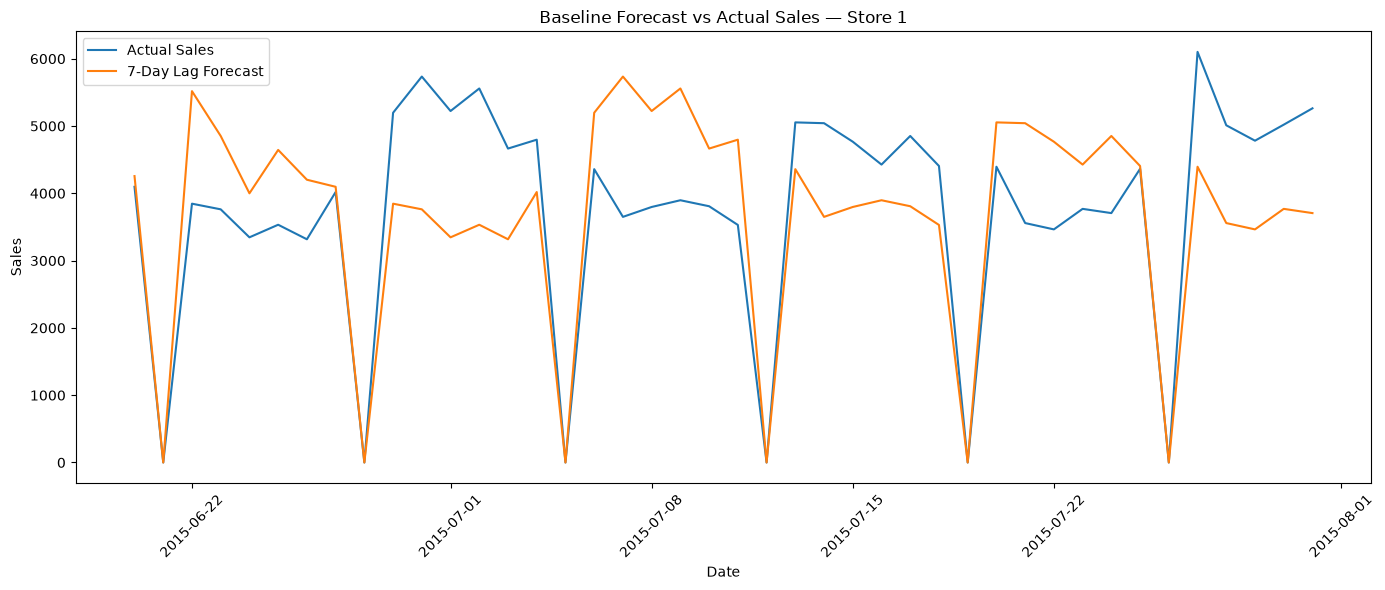

In [122]:
plt.figure(figsize=(14, 6))

plt.plot(
    store_plot["Date"],
    store_plot["Sales"],
    label="Actual Sales"
)

plt.plot(
    store_plot["Date"],
    store_plot["BaselinePrediction"],
    label="7-Day Lag Forecast"
)

plt.title(
    f"Baseline Forecast vs Actual Sales — Store {store_id}"
)

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Baseline Forecast

A naive seven-day lag forecast was established as the initial benchmark.
For each store-date observation, sales from exactly seven calendar days
earlier were used as the predicted sales value.

The seven-day lag was selected because exploratory analysis identified a
strong weekly demand pattern. This provides a meaningful benchmark against
which more sophisticated forecasting models can be evaluated.

Forecast accuracy is evaluated using Mean Absolute Error (MAE), Root Mean
Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE). WAPE
provides an overall relative error measure while avoiding some of the issues
associated with percentage errors when actual sales can equal zero.

A machine-learning model will only be considered useful if it provides a
meaningful improvement over this simple historical benchmark.

### Baseline Performance

The naive seven-day lag forecast produced an MAE of approximately 1,888,
an RMSE of 2,629, and a WAPE of 31.45% on the six-week validation period.

The RMSE being higher than the MAE indicates the presence of relatively large
forecasting errors for some store-date observations. A WAPE of 31.45% also
shows that simply assuming weekly sales will repeat leaves substantial room
for improvement.

These results establish the benchmark that subsequent machine-learning models
must outperform.

### Baseline Forecast Interpretation

The seven-day lag baseline captures much of the recurring weekly structure in
Store 1's sales, including the regular zero-sales periods. This confirms that
recent weekly sales history contains useful forecasting information.

However, the baseline frequently underestimates or overestimates the magnitude
of sales on operating days. In several periods, actual sales increase
substantially while the seven-day forecast remains considerably lower, while
the opposite occurs in other periods.

This suggests that weekly historical sales alone are insufficient to explain
changes in demand. Additional information such as promotions, calendar
effects, store characteristics, recent demand trends, and volatility may help
produce more accurate forecasts.

In [135]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

In [136]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [137]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [138]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [139]:
linear_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [142]:
linear_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print(linear_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Store', 'Open', 'Promo',
                                                   'SchoolHoliday',
                                                   'CompetitionDistance',
                                                   'Promo2', 'Year', 'Month',
                                                   'WeekOfYear', 'Quarter',
                                                   'DayOfWeek', 'Month_sin',
                                                   'Month_cos', 'DayOfWeek_sin',
                                  

In [141]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Store', 'Open', 'Promo', 'SchoolHoliday',
                                  'CompetitionDistance', 'Promo2', 'Year',
                                  'Month', 'WeekOfYear', 'Quarter', 'DayOfWeek',
                                  'Month_sin', 'Month_cos', 'DayOfWeek_sin',
                                  'DayOfWeek_cos', 'Sales_Lag_1', 'Sales_Lag_7',
                                  'Sales_Lag_14', 'Sales_Lag_28',
                                  'RollingMean_7', 'RollingMean_14',
                                  'RollingMean_28', 'RollingStd_7',
                                  'RollingStd_28', 'RollingMin_7',
                                  'RollingMax_7']),
                    

In [144]:
for col in categorical_features:
    print(f"\n{col}")
    print(df_model_clean[col].map(type).value_counts())
    print("Unique values:", df_model_clean[col].unique())


StateHoliday
StateHoliday
<class 'str'>    849877
<class 'int'>    131072
Name: count, dtype: int64
Unique values: ['0' 'b' 'a' 'c' 0]

StoreType
StoreType
<class 'str'>    980949
Name: count, dtype: int64
Unique values: <StringArray>
['c', 'a', 'd', 'b']
Length: 4, dtype: str

Assortment
Assortment
<class 'str'>    980949
Name: count, dtype: int64
Unique values: <StringArray>
['a', 'c', 'b']
Length: 3, dtype: str


In [145]:
for col in categorical_features:
    df_model_clean[col] = (
        df_model_clean[col]
        .astype(str)
    )

In [146]:
for col in categorical_features:
    print(col, df_model_clean[col].map(type).value_counts())

StateHoliday StateHoliday
<class 'str'>    980949
Name: count, dtype: int64
StoreType StoreType
<class 'str'>    980949
Name: count, dtype: int64
Assortment Assortment
<class 'str'>    980949
Name: count, dtype: int64


In [147]:
X = df_model_clean[features].copy()
y = df_model_clean["Sales"].copy()

X_train = X.loc[train_mask].copy()
X_valid = X.loc[valid_mask].copy()

y_train = y.loc[train_mask].copy()
y_valid = y.loc[valid_mask].copy()

In [148]:
for col in categorical_features:
    print(f"\n{col}")
    print(X_train[col].map(type).value_counts())


StateHoliday
StateHoliday
<class 'str'>    934119
Name: count, dtype: int64

StoreType
StoreType
<class 'str'>    934119
Name: count, dtype: int64

Assortment
Assortment
<class 'str'>    934119
Name: count, dtype: int64


In [149]:
linear_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [150]:
linear_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['Store','Open','Promo',...,'StateHoliday','StoreType','Assortment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis 

In [151]:
linear_pred = linear_pipeline.predict(X_valid)

print("Minimum prediction:", linear_pred.min())
print(
    "Number of negative predictions:",
    (linear_pred < 0).sum()
)

Minimum prediction: -2025.0411739537417
Number of negative predictions: 4224


In [152]:
linear_pred_clipped = np.maximum(
    linear_pred,
    0
)

print(
    "Negative predictions after clipping:",
    (linear_pred_clipped < 0).sum()
)

print(
    "Minimum prediction after clipping:",
    linear_pred_clipped.min()
)

Negative predictions after clipping: 0
Minimum prediction after clipping: 0.0


In [153]:
linear_metrics = evaluate_forecast(
    y_valid,
    linear_pred_clipped
)

linear_metrics

{'MAE': 693.4390654122703,
 'RMSE': np.float64(1048.4392302702593),
 'WAPE (%)': np.float64(11.551829301792054)}

In [154]:
model_results.append({
    "Model": "Linear Regression",
    **linear_metrics
})

results_df = pd.DataFrame(model_results)

results_df

,Model,MAE,RMSE,WAPE (%)
0,Naive 7-Day Lag,1887.986526,2629.305949,31.451499
1,Linear Regression,693.439065,1048.439230,11.551829


In [156]:
baseline_mae = baseline_metrics["MAE"]

results_df["MAE Improvement vs Baseline (%)"] = (
    (baseline_mae - results_df["MAE"])
    / baseline_mae
) * 100

results_df

,Model,MAE,RMSE,WAPE (%),MAE Improvement vs Baseline (%)
0,Naive 7-Day Lag,1887.986526,2629.305949,31.451499,0.000000
1,Linear Regression,693.439065,1048.439230,11.551829,63.270974


### Linear Regression

Linear Regression was trained as the first machine-learning forecasting model
to determine whether a relatively simple multivariate model could outperform
the seven-day naive baseline.

The model incorporates historical demand, calendar information, promotional
conditions, and store characteristics.

Because unconstrained Linear Regression can produce predictions below zero,
negative sales forecasts were clipped to zero before evaluation. The original
model produced 4,224 negative validation predictions, with a minimum predicted
value of approximately -2,025. Since negative sales are not meaningful for
this forecasting problem, zero was used as the lower bound for operational
predictions.

In [157]:
valid_results["LinearPrediction"] = linear_pred_clipped

In [158]:
store_id = 1

store_plot = (
    valid_results[
        valid_results["Store"] == store_id
    ]
    .sort_values("Date")
)

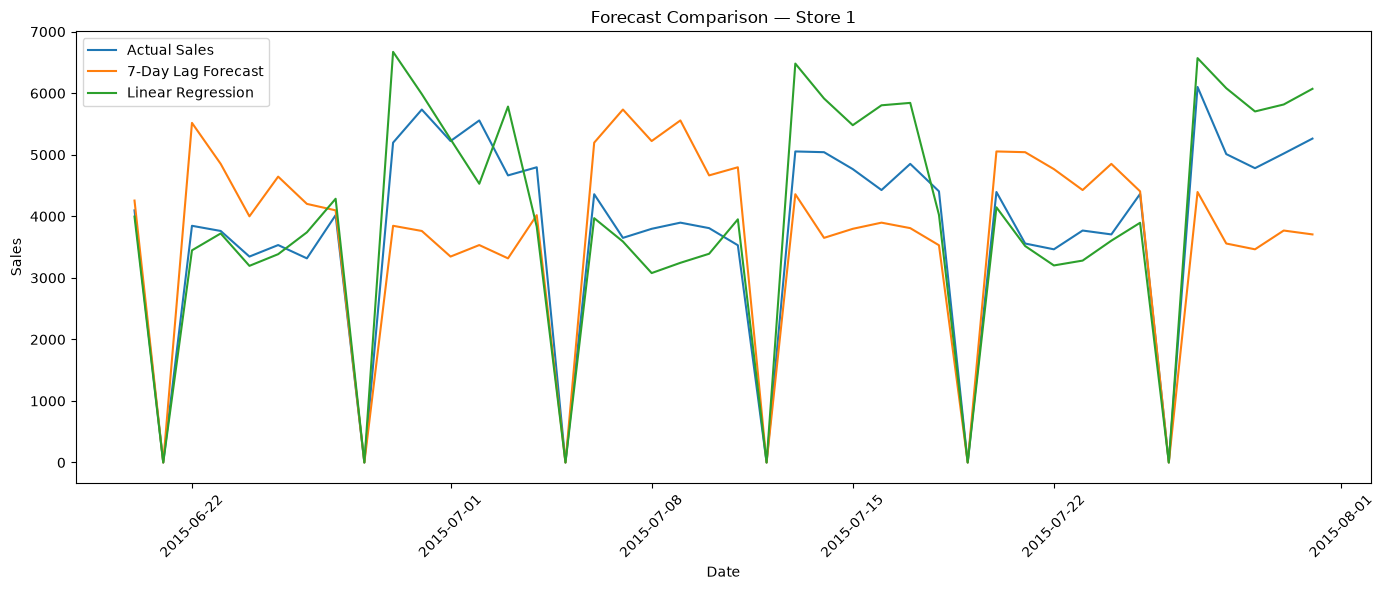

In [159]:
plt.figure(figsize=(14, 6))

plt.plot(
    store_plot["Date"],
    store_plot["Sales"],
    label="Actual Sales"
)

plt.plot(
    store_plot["Date"],
    store_plot["BaselinePrediction"],
    label="7-Day Lag Forecast"
)

plt.plot(
    store_plot["Date"],
    store_plot["LinearPrediction"],
    label="Linear Regression"
)

plt.title(
    f"Forecast Comparison — Store {store_id}"
)

plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [160]:
linear_residuals = (
    y_valid.values - linear_pred_clipped
)

pd.Series(linear_residuals).describe()

count    46830.000000
mean       -59.783225
std       1046.744564
min     -15407.833820
25%       -612.947627
50%        -33.339509
75%        384.443211
max      32697.835183
dtype: float64

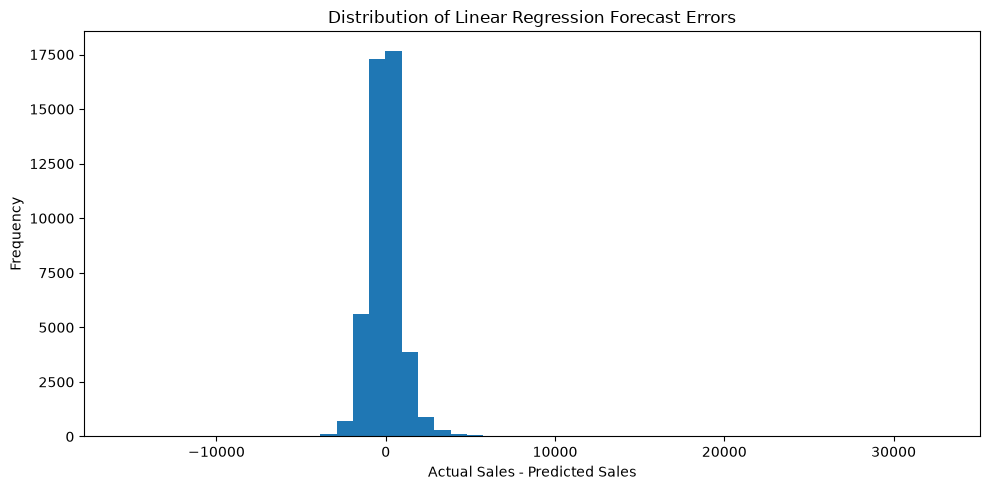

In [161]:
plt.figure(figsize=(10, 5))

plt.hist(
    linear_residuals,
    bins=50
)

plt.title("Distribution of Linear Regression Forecast Errors")
plt.xlabel("Actual Sales - Predicted Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [162]:
print(
    "Mean residual:",
    linear_residuals.mean()
)

print(
    "Median residual:",
    np.median(linear_residuals)
)

Mean residual: -59.783225066424095
Median residual: -33.33950853629176


In [163]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor

In [164]:
tree_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

In [165]:
tree_categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "ordinal",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
        )
    ]
)

In [166]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            tree_numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            tree_categorical_transformer,
            categorical_features
        )
    ]
)

In [167]:
hgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            tree_preprocessor
        ),
        (
            "model",
            HistGradientBoostingRegressor(
                learning_rate=0.1,
                max_iter=200,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                random_state=42
            )
        )
    ]
)

In [168]:
hgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            tree_preprocessor
        ),
        (
            "model",
            HistGradientBoostingRegressor(
                learning_rate=0.1,
                max_iter=200,
                max_leaf_nodes=31,
                l2_regularization=1.0,
                random_state=42
            )
        )
    ]
)

In [169]:
hgb_pipeline.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['Store','Open','Promo',...,'StateHoliday','StoreType','Assortment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis 

In [170]:
hgb_pred = hgb_pipeline.predict(
    X_valid
)

hgb_pred = np.maximum(
    hgb_pred,
    0
)

In [171]:
hgb_metrics = evaluate_forecast(
    y_valid,
    hgb_pred
)

hgb_metrics

{'MAE': 538.0630531326894,
 'RMSE': np.float64(852.9253211144782),
 'WAPE (%)': np.float64(8.963458872474293)}

In [172]:
model_results.append({
    "Model": "HistGradientBoosting",
    **hgb_metrics
})

results_df = pd.DataFrame(model_results)

results_df["MAE Improvement vs Baseline (%)"] = (
    (baseline_metrics["MAE"] - results_df["MAE"])
    / baseline_metrics["MAE"]
) * 100

results_df

,Model,MAE,RMSE,WAPE (%),MAE Improvement vs Baseline (%)
0,Naive 7-Day Lag,1887.986526,2629.305949,31.451499,0.000000
1,Linear Regression,693.439065,1048.439230,11.551829,63.270974
2,HistGradientBoosting,538.063053,852.925321,8.963459,71.500694


## Model Comparison

Three forecasting approaches were evaluated using the same chronological
validation period.

The naive seven-day lag model produced a WAPE of 31.45% and an MAE of
approximately 1,888. Linear Regression substantially improved performance,
reducing WAPE to 11.55% and MAE to approximately 693.

HistGradientBoosting achieved the strongest performance, with an MAE of
approximately 538, RMSE of 853, and WAPE of 8.96%. This represents a 71.50%
reduction in MAE relative to the naive baseline.

The improvement suggests that retail sales contain nonlinear relationships
between recent demand, promotions, calendar effects, and store
characteristics that are not fully captured by a simple linear model.

HistGradientBoosting was therefore selected as the best-performing model for
the subsequent analysis.

In [173]:
valid_results = df_model_clean.loc[
    valid_mask,
    ["Date", "Store", "Sales", "Promo", "Open"]
].copy()

valid_results["BaselinePrediction"] = baseline_pred
valid_results["LinearPrediction"] = linear_pred_clipped
valid_results["HGBPrediction"] = hgb_pred

valid_results.head()

,Date,Store,Sales,Promo,Open,BaselinePrediction,LinearPrediction,HGBPrediction
900,2015-06-20,1,4097,0,1,4256.0,3996.095351,3965.289069
901,2015-06-21,1,0,0,0,0.0,0.000000,9.121632
902,2015-06-22,1,3846,0,1,5518.0,3447.450501,4038.427435
903,2015-06-23,1,3762,0,1,4852.0,3721.525272,3728.533384
904,2015-06-24,1,3346,0,1,4000.0,3195.162165,3599.848338


In [174]:
valid_results["ForecastError"] = (
    valid_results["Sales"]
    - valid_results["HGBPrediction"]
)

valid_results["AbsoluteError"] = (
    valid_results["ForecastError"].abs()
)

valid_results[
    [
        "Sales",
        "HGBPrediction",
        "ForecastError",
        "AbsoluteError"
    ]
].describe()

,Sales,HGBPrediction,ForecastError,AbsoluteError
count,46830.000000,46830.000000,46830.000000,46830.000000
mean,6002.850694,6056.869217,-54.018523,538.063053
std,3726.141427,3710.334045,851.222107,661.799899
min,0.000000,0.000000,-16742.105925,0.000000
25%,4091.000000,4162.724121,-426.718692,106.369049
50%,5902.000000,5983.712239,0.000000,363.254130
75%,7964.000000,8042.713634,295.542138,745.589457
max,41551.000000,29762.863265,29971.985865,29971.985865


In [175]:
print(
    "Mean forecast error:",
    valid_results["ForecastError"].mean()
)

print(
    "Median forecast error:",
    valid_results["ForecastError"].median()
)

Mean forecast error: -54.018523175001086
Median forecast error: 0.0


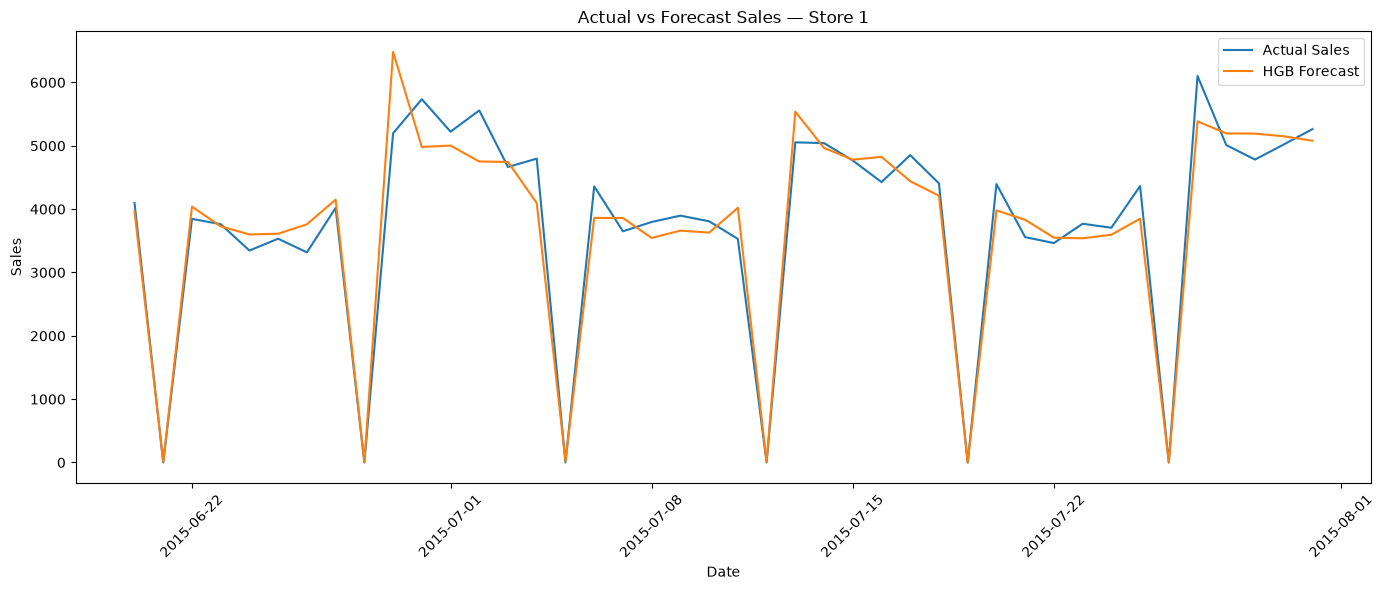

In [176]:
store_plot = (
    valid_results[
        valid_results["Store"] == 1
    ]
    .sort_values("Date")
)

plt.figure(figsize=(14, 6))

plt.plot(
    store_plot["Date"],
    store_plot["Sales"],
    label="Actual Sales"
)

plt.plot(
    store_plot["Date"],
    store_plot["HGBPrediction"],
    label="HGB Forecast"
)

plt.title("Actual vs Forecast Sales — Store 1")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Actual vs Forecast — Store 1

The HistGradientBoosting forecast closely follows the observed sales pattern
for Store 1 during the validation period. The model successfully captures the
recurring zero-sales periods as well as much of the variation in sales on
operating days.

The largest differences occur during sharper changes in demand, where the
model occasionally overestimates or underestimates the magnitude of sales.
This is consistent with the broader error analysis, which showed strong
typical forecasting performance but larger errors for some unusual demand
events.

Overall, the visualization supports the quantitative evaluation and indicates
that the selected model captures both recurring weekly behavior and changes
in the general level of store demand.

### Forecast Error Analysis

The selected HistGradientBoosting model achieved an average absolute forecast
error of approximately 538 sales-value units across the validation period.

The mean forecast error was approximately -54, indicating a small overall
tendency to overpredict sales. Relative to average observed sales of
approximately 6,003, this represents a relatively small systematic bias.

The median forecast error was zero, while 50% of forecast errors fell between
approximately -427 and 296 sales-value units. However, several substantially
larger errors remained, particularly during unusually high-sales observations.

Overall, the model demonstrates strong typical forecasting performance while
still experiencing difficulty with extreme demand events.

In [178]:
from sklearn.inspection import permutation_importance

sample_size = min(10000, len(X_valid))

X_importance = X_valid.sample(
    n=sample_size,
    random_state=42
)

y_importance = y_valid.loc[X_importance.index]

In [179]:
importance_result = permutation_importance(
    hgb_pipeline,
    X_importance,
    y_importance,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

In [180]:
feature_importance = pd.DataFrame({
    "Feature": X_importance.columns,
    "Importance": importance_result.importances_mean
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance.head(10)

,Feature,Importance
0,Open,1176.984693
1,Promo,417.596859
2,RollingMean_28,278.986656
3,Sales_Lag_14,220.722515
4,Sales_Lag_1,203.752107
5,Sales_Lag_28,175.996553
6,Sales_Lag_7,138.814354
7,DayOfWeek,98.465171
8,RollingMax_7,30.599409
9,WeekOfYear,26.372851


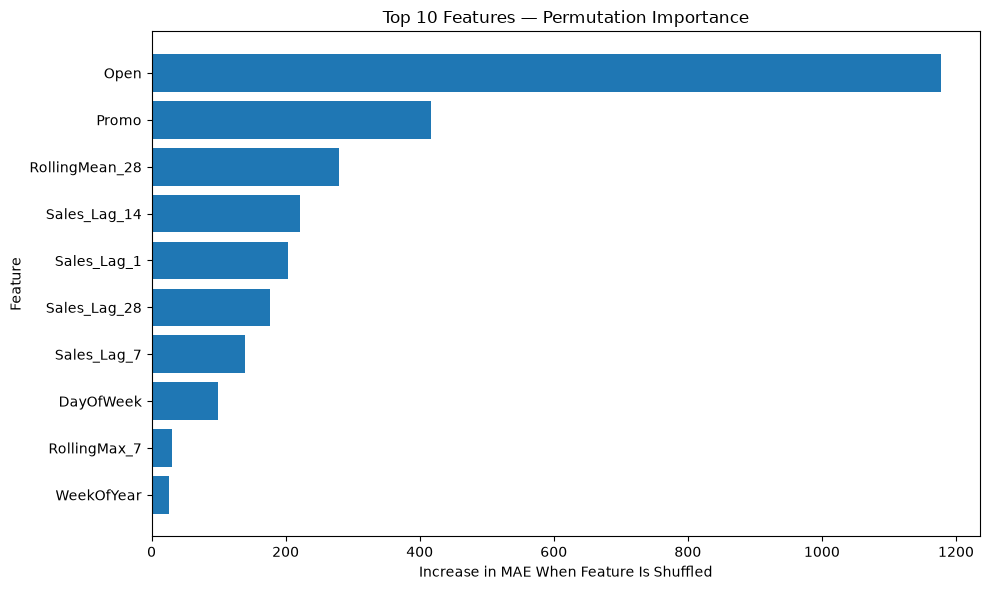

In [181]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 10 Features — Permutation Importance")
plt.xlabel("Increase in MAE When Feature Is Shuffled")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Forecast Bias

The mean forecast error was approximately -54 sales-value units, indicating
a slight tendency for the model to overpredict sales. Relative to average
validation sales of approximately 6,003, this represents a small overall
bias of about 0.9%.

The median forecast error was zero, suggesting that the model does not exhibit
a substantial systematic tendency to overforecast or underforecast across
typical observations. However, larger errors remain for some unusually high
or volatile sales periods.

In [182]:
feature_importance.head(10)

,Feature,Importance
0,Open,1176.984693
1,Promo,417.596859
2,RollingMean_28,278.986656
3,Sales_Lag_14,220.722515
4,Sales_Lag_1,203.752107
5,Sales_Lag_28,175.996553
6,Sales_Lag_7,138.814354
7,DayOfWeek,98.465171
8,RollingMax_7,30.599409
9,WeekOfYear,26.372851


### Feature Importance

Permutation importance was used to investigate which variables contributed
most strongly to the selected model's forecasting performance.

Store operating status (`Open`) was the most influential feature, followed by
promotion status (`Promo`). This indicates that known operating schedules and
planned promotional activity provide substantial information about expected
sales.

Historical demand was also highly influential. The 28-day rolling average and
sales lagged by 1, 7, 14, and 28 days all ranked among the most important
features. This demonstrates that both recent demand and recurring historical
patterns contribute to forecast accuracy.

Calendar information also contributed to the model, with `DayOfWeek` and
`WeekOfYear` appearing among the ten most important features.

Overall, the feature-importance analysis suggests that future sales are driven
by a combination of store operating conditions, promotional activity, recent
demand levels, recurring historical sales patterns, and calendar effects.

Permutation importance reflects the deterioration in predictive performance
when a feature is disrupted and should not be interpreted as a causal effect
or as a percentage contribution to sales.

In [183]:
store_typical_sales = (
    df_model_clean
    .loc[train_mask]
    .groupby("Store")["Sales"]
    .median()
    .rename("TypicalSales")
)

In [184]:
planning_table = valid_results.merge(
    store_typical_sales,
    on="Store",
    how="left"
)

In [185]:
planning_table["DemandRatio"] = (
    planning_table["HGBPrediction"]
    / planning_table["TypicalSales"]
)

In [186]:
planning_table.loc[
    planning_table["TypicalSales"] <= 0,
    "DemandRatio"
] = np.nan

In [187]:
planning_table[
    [
        "Date",
        "Store",
        "HGBPrediction",
        "TypicalSales",
        "DemandRatio"
    ]
].head(10)

,Date,Store,HGBPrediction,TypicalSales,DemandRatio
0,2015-06-20,1,3965.289069,4373.5,0.906663
1,2015-06-21,1,9.121632,4373.5,0.002086
2,2015-06-22,1,4038.427435,4373.5,0.923386
3,2015-06-23,1,3728.533384,4373.5,0.852528
4,2015-06-24,1,3599.848338,4373.5,0.823105
5,2015-06-25,1,3611.572285,4373.5,0.825785
6,2015-06-26,1,3760.347466,4373.5,0.859803
7,2015-06-27,1,4150.066761,4373.5,0.948912
8,2015-06-28,1,2.898087,4373.5,0.000663
9,2015-06-29,1,6482.478391,4373.5,1.482218


In [188]:
conditions = [
    planning_table["Open"] == 0,
    planning_table["DemandRatio"] < 0.80,
    planning_table["DemandRatio"] <= 1.20,
    planning_table["DemandRatio"] > 1.20
]

choices = [
    "Closed",
    "Low Demand",
    "Normal Demand",
    "High Demand"
]

planning_table["DemandSignal"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

In [189]:
planning_table["DemandSignal"].value_counts()

DemandSignal
Normal Demand    22563
High Demand      14718
Closed            6548
Low Demand        3001
Name: count, dtype: int64

In [190]:
planning_output = planning_table[
    [
        "Date",
        "Store",
        "Promo",
        "HGBPrediction",
        "TypicalSales",
        "DemandRatio",
        "DemandSignal"
    ]
].copy()

planning_output.head(15)

,Date,Store,Promo,HGBPrediction,TypicalSales,DemandRatio,DemandSignal
0,2015-06-20,1,0,3965.289069,4373.5,0.906663,Normal Demand
1,2015-06-21,1,0,9.121632,4373.5,0.002086,Closed
2,2015-06-22,1,0,4038.427435,4373.5,0.923386,Normal Demand
3,2015-06-23,1,0,3728.533384,4373.5,0.852528,Normal Demand
4,2015-06-24,1,0,3599.848338,4373.5,0.823105,Normal Demand
5,2015-06-25,1,0,3611.572285,4373.5,0.825785,Normal Demand
6,2015-06-26,1,0,3760.347466,4373.5,0.859803,Normal Demand
7,2015-06-27,1,0,4150.066761,4373.5,0.948912,Normal Demand
8,2015-06-28,1,0,2.898087,4373.5,0.000663,Closed
9,2015-06-29,1,1,6482.478391,4373.5,1.482218,High Demand


In [191]:
planning_output["HGBPrediction"] = (
    planning_output["HGBPrediction"].round(0)
)

planning_output["TypicalSales"] = (
    planning_output["TypicalSales"].round(0)
)

planning_output["DemandRatio"] = (
    planning_output["DemandRatio"].round(2)
)

planning_output.head(15)

,Date,Store,Promo,HGBPrediction,TypicalSales,DemandRatio,DemandSignal
0,2015-06-20,1,0,3965.0,4374.0,0.91,Normal Demand
1,2015-06-21,1,0,9.0,4374.0,0.00,Closed
2,2015-06-22,1,0,4038.0,4374.0,0.92,Normal Demand
3,2015-06-23,1,0,3729.0,4374.0,0.85,Normal Demand
4,2015-06-24,1,0,3600.0,4374.0,0.82,Normal Demand
5,2015-06-25,1,0,3612.0,4374.0,0.83,Normal Demand
6,2015-06-26,1,0,3760.0,4374.0,0.86,Normal Demand
7,2015-06-27,1,0,4150.0,4374.0,0.95,Normal Demand
8,2015-06-28,1,0,3.0,4374.0,0.00,Closed
9,2015-06-29,1,1,6482.0,4374.0,1.48,High Demand


## Demand Planning Framework

The sales forecasts were translated into a simple store-level demand planning
signal to make the model outputs easier to interpret operationally.

Each forecast was compared with the median historical sales of the
corresponding store. This allows predicted demand to be evaluated relative to
the store's own typical sales level rather than applying the same absolute
threshold across stores with different sales volumes.

The following illustrative planning rules were applied:

- **Closed:** The store is not scheduled to operate.
- **Low Demand:** Forecast is below 80% of the store's typical sales.
- **Normal Demand:** Forecast is between 80% and 120% of typical sales.
- **High Demand:** Forecast exceeds 120% of typical sales.

These categories can help operational teams identify stores and dates that may
require additional preparation, staffing, or replenishment attention.

The thresholds are illustrative business rules rather than optimized inventory
policies and would require calibration using operational costs and business
requirements before production deployment.

In [192]:
planning_table["DemandSignal"].value_counts()

DemandSignal
Normal Demand    22563
High Demand      14718
Closed            6548
Low Demand        3001
Name: count, dtype: int64

In [193]:
planning_output.head(15)

,Date,Store,Promo,HGBPrediction,TypicalSales,DemandRatio,DemandSignal
0,2015-06-20,1,0,3965.0,4374.0,0.91,Normal Demand
1,2015-06-21,1,0,9.0,4374.0,0.00,Closed
2,2015-06-22,1,0,4038.0,4374.0,0.92,Normal Demand
3,2015-06-23,1,0,3729.0,4374.0,0.85,Normal Demand
4,2015-06-24,1,0,3600.0,4374.0,0.82,Normal Demand
5,2015-06-25,1,0,3612.0,4374.0,0.83,Normal Demand
6,2015-06-26,1,0,3760.0,4374.0,0.86,Normal Demand
7,2015-06-27,1,0,4150.0,4374.0,0.95,Normal Demand
8,2015-06-28,1,0,3.0,4374.0,0.00,Closed
9,2015-06-29,1,1,6482.0,4374.0,1.48,High Demand


## Conclusion

This project developed a store-level retail demand forecasting system using
historical Rossmann sales data.

Exploratory analysis showed that sales vary substantially across time, days of
the week, promotional periods, store types, and individual stores. Historical
sales patterns were therefore combined with calendar, promotional, and
store-level information to develop predictive models.

Three forecasting approaches were evaluated using chronological validation:

- Naive 7-Day Lag: MAE = 1,888, WAPE = 31.45%
- Linear Regression: MAE = 693, WAPE = 11.55%
- HistGradientBoosting: MAE = 538, WAPE = 8.96%

HistGradientBoosting achieved the strongest forecasting performance, reducing
MAE by approximately 71.5% relative to the naive seven-day benchmark.

Feature-importance analysis showed that store operating status, promotions,
recent historical sales, rolling demand levels, and calendar patterns were
important contributors to forecast accuracy.

The forecasts were subsequently converted into a simple demand-planning
framework that compares predicted sales with each store's historical typical
sales. This allows store-date observations to be classified as Closed, Low
Demand, Normal Demand, or High Demand.

Approximately 31.4% of validation store-days were classified as High Demand,
providing a mechanism for operational teams to prioritize locations expected
to experience unusually strong demand.


## Business Recommendations

1. **Use forecasts to identify unusually high-demand periods.**
   Stores receiving High Demand signals can be prioritized for operational
   preparation before the expected increase in activity.

2. **Incorporate promotional plans into demand forecasting.**
   Promotion status was one of the most important predictive features and
   promotional periods were associated with substantially higher historical
   sales.

3. **Use store-specific demand benchmarks.**
   Demand should be evaluated relative to each store's historical behavior
   rather than using a single sales threshold across all locations.

4. **Monitor volatile and exceptional demand periods.**
   Although the selected model performs strongly overall, unusually large
   sales spikes remain more difficult to predict and may require additional
   monitoring.

5. **Integrate the forecasting signal with operational planning.**
   Forecasts can support decisions involving staffing, replenishment
   readiness, promotional preparation, and store-level resource allocation.


## Limitations

The Rossmann dataset provides store-level sales value rather than SKU-level
unit demand. Therefore, the forecasts should be interpreted as store-level
demand signals and cannot directly determine the quantity of individual
products that should be ordered.

The demand categories used in this project are illustrative business rules.
Production thresholds should be calibrated using inventory costs, staffing
requirements, service levels, and other operational objectives.

The validation design represents a rolling one-step-ahead forecasting setting:
recently observed sales are available when constructing lag and rolling
features for subsequent dates. It should therefore not be interpreted as a
fixed-origin 42-day-ahead forecast.

Future implementations could incorporate SKU-level sales, inventory levels,
lead times, pricing, stockouts, weather, local events, and additional external
variables to support more detailed inventory optimization.

In [194]:
from pathlib import Path

Path("../outputs").mkdir(
    parents=True,
    exist_ok=True
)

In [195]:
from pathlib import Path

Path("../outputs").mkdir(
    parents=True,
    exist_ok=True
)

In [196]:
print("Model exists:", "hgb_pipeline" in globals())
print("Planning output exists:", "planning_output" in globals())

Model exists: True
Planning output exists: True


In [197]:
from pathlib import Path
import joblib

# Locate the project directory
current_dir = Path.cwd()

if current_dir.name == "notebook":
    project_root = current_dir.parent
else:
    project_root = current_dir

print("Project directory:", project_root)

# Create folders if necessary
models_dir = project_root / "models"
outputs_dir = project_root / "outputs"

models_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# Save trained model
model_path = models_dir / "final_demand_forecasting_model.pkl"

joblib.dump(
    hgb_pipeline,
    model_path
)

# Save demand planning results
output_path = outputs_dir / "demand_planning_signals.csv"

planning_output.to_csv(
    output_path,
    index=False
)

print("Model saved:", model_path.exists())
print("Planning output saved:", output_path.exists())
print("Model path:", model_path.resolve())
print("Output path:", output_path.resolve())

Project directory: c:\Users\DELL\Desktop\demand-forecasting-inventory-planning
Model saved: True
Planning output saved: True
Model path: C:\Users\DELL\Desktop\demand-forecasting-inventory-planning\models\final_demand_forecasting_model.pkl
Output path: C:\Users\DELL\Desktop\demand-forecasting-inventory-planning\outputs\demand_planning_signals.csv


In [198]:
from pathlib import Path
import joblib

# Identify the project directory
current_dir = Path.cwd()

if current_dir.name == "notebook":
    project_root = current_dir.parent
else:
    project_root = current_dir

print("Project directory:", project_root)

# Create folders
models_dir = project_root / "models"
outputs_dir = project_root / "outputs"

models_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# Save trained model
model_path = models_dir / "final_demand_forecasting_model.pkl"
joblib.dump(hgb_pipeline, model_path)

# Save planning results
output_path = outputs_dir / "demand_planning_signals.csv"
planning_output.to_csv(output_path, index=False)

# Verify
print("Model saved:", model_path.exists())
print("Planning output saved:", output_path.exists())
print("Model path:", model_path.resolve())
print("Output path:", output_path.resolve())

Project directory: c:\Users\DELL\Desktop\demand-forecasting-inventory-planning
Model saved: True
Planning output saved: True
Model path: C:\Users\DELL\Desktop\demand-forecasting-inventory-planning\models\final_demand_forecasting_model.pkl
Output path: C:\Users\DELL\Desktop\demand-forecasting-inventory-planning\outputs\demand_planning_signals.csv
